# COMET — GRN dictionary + ATAC-led velocity (cleaned)

Unpaired scRNA + scATAC → per-cell GRN mixing + differentiation velocity.

**What changed vs. the previous version**
- All paths / run tags are set once in **Config** below.
- GRN mixing no longer collapses to hard assignment: archetype (not centroid) init, a
  shared-base + residual-atom reconstruction, and a geometry-derived soft-target prior
  (replaces the entropy/Dirichlet knobs). Temperature is fixed at 1.0 everywhere,
  including evaluation/saving (the old code sharpened to 0.1, which *displayed* hard
  assignment even when weights were soft).
- Velocity direction now comes from the **ATAC→RNA lead** propagated through the learned
  GRN, not from `steady(RNA) − RNA` (which is ~0 at a self-consistent fixed point and
  points inward at the origin). No pseudotime is used in the velocity.
- **Rooted 2D field (the origin fix).** A progenitor's velocity is a superposition of its
  fates, so a single averaged vector collapses to ~0 at the branch point. Rather than fight
  that, we (i) locate the **root** from the ATAC→RNA discrepancy (open-but-quiet chromatin
  priming, maximal in multipotent cells), (ii) build a **geodesic progression** `τ` = graph
  distance from that root — monotone from the origin by construction, so `+∇τ` fans cleanly
  outward into every branch, and (iii) let the GRN/ATAC velocity refine the direction only
  where it points *forward* (gate `c = max(0, cos(V_dir, ∇τ))`), which deletes the inward/
  backward arrows at the origin. Topology-agnostic (branching / linear / bilinear) and still
  pseudotime-free — `τ` is an internal manifold coordinate, not the external FACS ordering.
  The **same field builder** feeds the training GIF and the final plot.
- One arrow plot only (scVelo-style stream), fed by the rooted field.

---

## Config — set everything here

In [1]:
import os

# ── file system ───────────────────────────────────────────────────────────────
BASE     = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
RUN_TAG  = "75_hvg_fix2"                       # <- the {61} / {75_hvg} suffix; change per run
OUT_DIR  = f"bert_grn_out_{RUN_TAG}"      # everything this run writes goes here
os.makedirs(OUT_DIR, exist_ok=True)

# ── input files (relative to BASE) ────────────────────────────────────────────
RNA_H5AD      = f"{BASE}/velten_rna.h5ad"
PEAK_TF_MTX   = f"{BASE}/peak_tf.mtx"
TF_NAMES_TXT  = f"{BASE}/tf_names.txt"
PEAK_GENE_CSV = f"{BASE}/peak_gene.csv"
PEAKS_TXT     = f"{BASE}/peaks.txt"
ATAC_MTX      = f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz"
ATAC_PEAKS    = f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz"
DECIPHER_NPZ  = f"{BASE}/models/decipher_outputs2/decipher_embeddings.npz"

# optional external comparison file (only used by the CellOracle appendix)
CELLORACLE_A  = f"{BASE}/models/bert_grn_out/A_learned.npy"

# ── column names / keys ───────────────────────────────────────────────────────
PSEUDOTIME_KEY = "facs_pseudotime"        # obs column, used ONLY for plot coloring
DECIPHER_BASIS = "X_decipher"             # for the scanpy marker-gene panel

# ── model / data hyperparameters ──────────────────────────────────────────────
N_TOP_HVG   = 3000
D_ATOMS     = 4        # number of GRN dictionary atoms (archetypes)
NUM_RUNS    = 1
N_EPOCHS    = 120
PHASE1_EPOCHS = 40
BATCH_SIZE  = 512
NEIGHBOR_SPACE = "decipher"               # "decipher" | "pca" | "latent"

# GRN-mixing controls
GEO_TAU_SCALE = 0.5     # smaller -> sharper geometric targets q (less mixing)
LAMBDA_GRN    = 1.0     # weight of GRN-propagated lead inside the velocity disequilibrium

# Velocity 2D-field assembly (visualization only; does NOT touch the high-dim V_pred,
# so run-to-run reproducibility of the inferred velocity is unchanged).
VEL_FIELD_K     = 20    # kNN for the geodesic graph, tau gradient, and grid interpolation
VEL_ROOT_FRAC   = 0.02  # fraction of top chromatin-primed cells taken as the origin/root set
VEL_SPEED_FLOOR = 0.6   # arrow-speed floor (0.6–1.0 → fairly uniform streamlines; origin never starves)

MARKER_GENES = ['CD34', 'MPO', 'LYZ', 'GATA1', 'SPI1', 'CEBPA']

## Imports

In [2]:
import json
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
import scanpy as sc
from scipy.sparse import lil_matrix, issparse
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.decomposition import PCA, NMF
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, MiniBatchKMeans

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, RandomSampler

import matplotlib.pyplot as plt

## Helper functions

In [3]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    denom = np.logical_or(a, b).sum()
    return 0.0 if denom == 0 else np.logical_and(a, b).sum() / denom

def top_support_mask(vec, frac=0.05):
    vec = np.abs(np.asarray(vec).ravel())
    k = max(1, int(np.ceil(frac * vec.size)))
    mask = np.zeros(vec.size, dtype=bool)
    mask[np.argpartition(vec, -k)[-k:]] = True
    return mask

def zscore_cols(A, eps=1e-8):
    """Per-gene (per-column) z-score across cells."""
    A = np.asarray(A, dtype=np.float32)
    return (A - A.mean(axis=0, keepdims=True)) / (A.std(axis=0, keepdims=True) + eps)

## Step 1: Load RNA, normalize, select HVGs, define universe

In [4]:
# 1. Load + standard scanpy normalization
rna_adata = ad.read_h5ad(RNA_H5AD)
print("Normalizing and log-transforming RNA counts...")
sc.pp.normalize_total(rna_adata, target_sum=1e4)
sc.pp.log1p(rna_adata)

# 2. HVG selection (kept, but TFs are always protected below)
sc.pp.highly_variable_genes(rna_adata, n_top_genes=N_TOP_HVG, subset=False)
hvg_genes = set(rna_adata.var_names[rna_adata.var['highly_variable']])

gene_names_all  = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
X_full = as_dense(rna_adata.X).astype(np.float32)

# 3. Context files
peak_tf = scipy.io.mmread(PEAK_TF_MTX).tocsr()
motif_tf_names  = open(TF_NAMES_TXT).read().strip().split()
motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}

peak_gene   = pd.read_csv(PEAK_GENE_CSV, sep="\t")
peaks       = pd.read_csv(PEAKS_TXT, header=None)[0].astype(str).tolist()
peak_to_idx = {p: i for i, p in enumerate(peaks)}

# 4. Target genes = in peaks AND (HVG OR functional TF).  TFs protected.
genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
A_tfs = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)
A_genes = np.array([
    g for g in gene_names_all
    if (g in genes_in_peaks and g in hvg_genes) or g in A_tfs
], dtype=str)

print(f"Target genes (A_genes): {len(A_genes)}  |  TFs (A_tfs): {len(A_tfs)}")

# 5. Slices
gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx   = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
X    = X_full[:, gene_idx]     # (N, G) normalized HVG expression
X_TF = X_full[:, tf_idx]       # (N, T) normalized TF expression
sub_g2i = {g: i for i, g in enumerate(A_genes)}

Normalizing and log-transforming RNA counts...
Target genes (A_genes): 3016  |  TFs (A_tfs): 277


## Step 2: Build M (gene × TF motif-accessibility mask)

In [5]:
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p, g = str(row["peak"]), str(row["gene"])
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# align M columns to TFs actually present in RNA
A_tfs  = np.array([t for t in A_tfs if t in motif_tf_to_idx], dtype=str)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
tf_col = np.array([motif_tf_to_idx[t] for t in A_tfs], dtype=int)

X_TF = X_full[:, tf_idx]                       # refresh after final TF filtering
M    = M_full[:, tf_col].toarray().astype(np.float32)
assert M.shape == (len(A_genes), len(A_tfs))

## Step 3: ATAC gene activity + population accessibility prior

In [6]:
print("Loading ATAC raw matrix...")
atac_raw = scipy.io.mmread(ATAC_MTX).tocsr()
atac_X   = atac_raw.T.astype(np.float32)       # cells x peaks

peaks_atac = pd.read_csv(ATAC_PEAKS, sep="\t")
peak_names = peaks_atac["Feature"].str.replace("_", ":", n=1).str.replace("_", "-", n=1).tolist()
peak_to_idx_atac = {p: i for i, p in enumerate(peak_names)}

def fix_peak(p):
    return str(p).replace("-", ":", 1)

P2, G2 = len(peak_names), len(A_genes)
peak_gene_mat_atac = lil_matrix((P2, G2), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p, g = fix_peak(row["peak"]), str(row["gene"])
    if p in peak_to_idx_atac and g in sub_g2i:
        peak_gene_mat_atac[peak_to_idx_atac[p], sub_g2i[g]] = 1.0
peak_gene_mat_atac = peak_gene_mat_atac.tocsr()

gene_activity = atac_X @ peak_gene_mat_atac                    # cells x genes
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = np.log1p(as_dense(gene_activity)).astype(np.float32)

cell_idx      = np.arange(X.shape[0])
atac_X        = as_dense(atac_X)[cell_idx]
gene_activity = gene_activity[cell_idx]

# population accessibility per gene, [0,1] — used by the ATAC direction penalty
gene_access   = gene_activity.mean(axis=0)
gene_access   = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

Loading ATAC raw matrix...


## Step 4: TF accessibility prior

In [7]:
def build_tf_access_prior(gene_activity, A_tfs, sub_g2i):
    T = len(A_tfs)
    tf_access = np.zeros(T, dtype=np.float32)
    for i, tf in enumerate(A_tfs):
        if tf in sub_g2i:
            tf_access[i] = float(gene_activity[:, sub_g2i[tf]].mean())
    lo, hi = tf_access.min(), tf_access.max()
    return (tf_access - lo) / (hi - lo + 1e-8)

TF_access_prior = build_tf_access_prior(gene_activity, A_tfs, sub_g2i)
TF_access_t = torch.tensor(TF_access_prior, dtype=torch.float32)
print(f"TF access prior: mean={TF_access_prior.mean():.3f}  "
      f"nonzero={np.mean(TF_access_prior > 0.05):.1%}")

TF access prior: mean=0.174  nonzero=76.9%


## Step 5: Load Decipher embedding

In [8]:
decipher_data = np.load(DECIPHER_NPZ)
Z_dec  = decipher_data["z"].astype(np.float32)   # (N, 10) latent
V_dec2 = decipher_data["v"].astype(np.float32)   # (N, 2)  visualization

pseudo      = rna_adata.obs[PSEUDOTIME_KEY].astype(np.float32)
pseudo_norm = (pseudo.values - pseudo.min()) / (np.ptp(pseudo.values) + 1e-8)

print(f"X {X.shape} | X_TF {X_TF.shape} | Z_dec {Z_dec.shape} | V_dec2 {V_dec2.shape}")

X (1035, 3016) | X_TF (1035, 277) | Z_dec (1035, 10) | V_dec2 (1035, 2)


## Step 6: Archetypes + geometry-derived soft mixing targets

The single most important change for GRN mixing. Instead of KMeans **centroids** (every
cell is nearest one centroid → hard assignment is optimal), we pick D **archetypes** =
extreme points of the manifold (branch tips + origin) via furthest-point sampling, then
define each cell's target mixing `q_i` as its softmax proximity to those archetypes.
Interior/transition cells get genuinely mixed `q`; committed tips get sharp `q`. This
is topology-agnostic (branching → tips+origin, linear → two ends, etc.).

In [9]:
def select_archetypes_fps(Z, D, seed=0):
    """Furthest-point sampling → indices of D extreme cells (manifold corners)."""
    rng = np.random.default_rng(seed)
    c   = Z.mean(axis=0)
    first = int(np.argmax(((Z - c) ** 2).sum(1)))
    idx = [first]
    dmin = ((Z - Z[first]) ** 2).sum(1)
    for _ in range(D - 1):
        nxt = int(np.argmax(dmin))
        idx.append(nxt)
        dmin = np.minimum(dmin, ((Z - Z[nxt]) ** 2).sum(1))
    return np.array(idx, dtype=int)

def geometric_soft_targets(Z, arch_idx, tau_scale=0.5):
    """q_i = softmax(-||z_i - z_arch||^2 / tau). Returns (N, D), rows sum to 1."""
    A = Z[arch_idx]                                    # (D, latent)
    d2 = ((Z[:, None, :] - A[None, :, :]) ** 2).sum(-1)  # (N, D)
    tau = np.median(d2) * tau_scale + 1e-8
    q = np.exp(-d2 / tau)
    q = q / (q.sum(1, keepdims=True) + 1e-8)
    return q.astype(np.float32)

arch_idx = select_archetypes_fps(Z_dec, D_ATOMS, seed=0)
q_target = geometric_soft_targets(Z_dec, arch_idx, tau_scale=GEO_TAU_SCALE)

_ent = -(q_target * np.log(q_target + 1e-8)).sum(1).mean()
print(f"Archetype cells: {arch_idx.tolist()}")
print(f"Soft-target entropy: {_ent:.3f} / {np.log(D_ATOMS):.3f} max "
      f"(want clearly between 0 and max)")

Archetype cells: [525, 386, 438, 939]
Soft-target entropy: 1.014 / 1.386 max (want clearly between 0 and max)


## Step 7: GRN dictionary model (shared base + residual atoms)

`predict_rna = A_base @ tf + Σ_d w_d (A_d @ tf)`. The shared base carries the common
regulatory program so the atoms only encode lineage-specific *residuals*. This removes
most of the reconstruction incentive to hard-assign — the crux that lets soft mixing
survive the likelihood term. The same effective per-cell GRN is reused by the velocity.

In [10]:
def init_atoms_from_soft_targets(X, q, M, A_tfs):
    """Soft-LFC init: each atom's weights come from cells weighted toward its archetype."""
    D = q.shape[1]
    G = X.shape[1]
    W_init = np.zeros((D, G, len(A_tfs)), dtype=np.float32)
    for d in range(D):
        w = q[:, d]                                   # (N,) soft membership
        wsum = w.sum() + 1e-8
        mean_in  = (X * w[:, None]).sum(0) / wsum
        mean_out = (X * (1 - w)[:, None]).sum(0) / ((1 - w).sum() + 1e-8)
        lfc = np.log1p(mean_in) - np.log1p(mean_out)  # (G,)
        for t_i in range(len(A_tfs)):
            col = M[:, t_i]
            if col.sum() == 0:
                continue
            lfc_masked = lfc * col
            rng = np.abs(lfc_masked).max() + 1e-8
            W_init[d, :, t_i] = lfc_masked / rng * 0.3
    return W_init


class GRNDictionary(nn.Module):
    def __init__(self, G, T, M, D=4):
        super().__init__()
        self.D, self.G, self.T = D, G, T
        self.W_raw  = nn.Parameter(torch.zeros(D, G, T))   # residual atoms
        self.W_base = nn.Parameter(torch.zeros(G, T))      # shared base
        self.register_buffer("M", torch.tensor(M, dtype=torch.float32))
        self.register_buffer("TF_access", torch.zeros(T))
        self.register_buffer("mean_tf",  torch.zeros(T))

    def init_from_atoms(self, W_init):
        with torch.no_grad():
            self.W_raw.copy_(torch.tensor(np.arctanh(np.clip(W_init, -0.95, 0.95)),
                                          dtype=torch.float32))
        print("GRN atoms initialized from archetype soft-LFC profiles (base starts at 0).")

    @property
    def A_dict(self):
        return torch.tanh(self.W_raw) * self.M.unsqueeze(0)   # (D, G, T)

    @property
    def A_base(self):
        return torch.tanh(self.W_base) * self.M               # (G, T)

    def _atom_term(self, X_in, weights):
        # sum_d w_d (X_in @ A_d.T) without materializing (B,G,T)
        P = torch.einsum('bt,dgt->dbg', X_in, self.A_dict)    # (D, B, G)
        return (P * weights.T.unsqueeze(-1)).sum(0)           # (B, G)

    def predict_rna(self, X_TF, weights):
        """Steady-state RNA prediction from TF expression (base + residual atoms)."""
        return (X_TF @ self.A_base.T) + self._atom_term(X_TF, weights)

    def production_from_lead(self, tf_lead, weights):
        """Effective per-cell GRN applied to the ATAC->RNA TF lead (for velocity)."""
        return (tf_lead @ self.A_base.T) + self._atom_term(tf_lead, weights)

    def effective_A(self, weights_vec):
        """weights_vec: (D,) -> (G, T) effective GRN including base."""
        return self.A_base + torch.einsum('d,dgt->gt', weights_vec, self.A_dict)

    def sparsity_loss(self):
        return torch.abs(self.A_dict).mean() + torch.abs(self.A_base).mean()

    def diversity_loss(self):
        """Keep residual atoms distinct in parameter AND prediction space."""
        A_flat = self.A_dict.reshape(self.D, -1)
        A_norm = F.normalize(A_flat, dim=1)
        eye = torch.eye(self.D, device=A_flat.device)
        param_div = ((A_norm @ A_norm.T) * (1 - eye)).abs().mean()

        pred = torch.einsum('dgt,t->dg', self.A_dict, self.mean_tf)
        pred = F.normalize(pred, dim=1)
        pred_div = ((pred @ pred.T) * (1 - eye)).abs().mean()
        return 0.5 * param_div + 0.5 * pred_div

    def tf_access_consistency_loss(self):
        closed = 1.0 - self.TF_access.clamp(0, 1)
        return (torch.abs(self.A_dict) * closed.unsqueeze(0).unsqueeze(0)).mean()


class CellStateEncoder(nn.Module):
    """RNA -> D mixing weights. Warm-started to reproduce the soft targets q (not hard labels)."""
    def __init__(self, G, D, hidden=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(G, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden // 2), nn.GELU(),
        )
        self.head = nn.Linear(hidden // 2, D)
        self.D = D

    def init_from_soft_targets(self, X, q, n_epochs=40, lr=1e-3, batch=256):
        """Distill the geometric soft targets q into the encoder (KL, not cross-entropy)."""
        print("Pre-training encoder to match geometric soft targets...")
        self.train()
        opt = torch.optim.Adam(self.parameters(), lr=lr)
        X_t = torch.tensor(X, dtype=torch.float32)
        q_t = torch.tensor(q, dtype=torch.float32)
        dl  = DataLoader(TensorDataset(X_t, q_t), batch_size=batch, shuffle=True)
        for ep in range(n_epochs):
            tot = 0.0
            for xb, qb in dl:
                logp = F.log_softmax(self.head(self.encoder(xb)), dim=-1)
                loss = (qb * (torch.log(qb + 1e-8) - logp)).sum(1).mean()   # KL(q||p)
                opt.zero_grad(); loss.backward(); opt.step()
                tot += loss.item()
            if ep % 10 == 0:
                print(f"  encoder pretrain epoch {ep}: KL={tot/len(dl):.4f}")
        print("Encoder pretraining complete.")

    def forward(self, rna, temperature=1.0):
        logits = self.head(self.encoder(rna))
        return F.softmax(logits / temperature, dim=-1)

## Step 8: Linear decoder (interpretable 2D embedding)

In [11]:
class LinearDecoder(nn.Module):
    def __init__(self, hidden, G, ld_dim=2):
        super().__init__()
        self.bottleneck = nn.Linear(hidden, ld_dim)
        self.W_dec = nn.Linear(ld_dim, G, bias=True)
        nn.init.normal_(self.W_dec.weight, std=0.01); nn.init.zeros_(self.W_dec.bias)
        nn.init.orthogonal_(self.bottleneck.weight);  nn.init.zeros_(self.bottleneck.bias)

    def forward(self, h):
        z = self.bottleneck(h)
        return z, self.W_dec(z)

    def reconstruction_loss(self, h, x):
        _, xh = self.forward(h)
        return F.mse_loss(xh, x)

    def ld_regularization_loss(self, h):
        z, _ = self.forward(h)
        zc = z - z.mean(0)
        var_loss = -torch.log((zc ** 2).mean(0) + 1e-4).mean()
        cov = (zc.T @ zc) / zc.shape[0]
        orth_loss = cov[0, 1].pow(2) + cov[1, 0].pow(2)
        return var_loss + orth_loss

    def get_gene_loadings(self):
        return self.W_dec.weight.detach().cpu().numpy()   # (G, 2)


def plot_ld_embedding(z_2d_rna, pseudo_norm, gene_loadings, A_genes,
                      z_2d_atac=None, highlight_genes=None, n_arrow_genes=15, save_path=None):
    has_atac = z_2d_atac is not None
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)

    ax = axes[0]
    if has_atac:
        ax.scatter(z_2d_atac[:, 0], z_2d_atac[:, 1], c='lightgray', s=6, alpha=0.4,
                   edgecolors='none', label='ATAC', rasterized=True)
    scv = ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1], c=pseudo_norm, cmap='viridis',
                     s=10, alpha=0.7, edgecolors='none', rasterized=True)
    plt.colorbar(scv, ax=ax, fraction=0.04, label='Pseudotime')
    ax.set_title('LD-VAE (RNA by pseudotime)', fontsize=10)
    ax.set_xlabel('LD 1'); ax.set_ylabel('LD 2')

    ax = axes[1]
    ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1], c='#2166ac', s=8, alpha=0.6,
               edgecolors='none', label=f'RNA (n={len(z_2d_rna)})', rasterized=True)
    if has_atac:
        ax.scatter(z_2d_atac[:, 0], z_2d_atac[:, 1], c='#d73027', s=8, alpha=0.6,
                   edgecolors='none', label=f'ATAC (n={len(z_2d_atac)})', rasterized=True)
    ax.set_title('LD-VAE (by modality)', fontsize=10); ax.legend(fontsize=8, frameon=False)
    ax.set_xlabel('LD 1'); ax.set_ylabel('LD 2')

    ax = axes[2]
    ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1], c='lightgray', s=4, alpha=0.3,
               edgecolors='none', rasterized=True)
    mags = np.linalg.norm(gene_loadings, axis=1)
    if highlight_genes is not None:
        hi = [i for i, g in enumerate(A_genes) if g in highlight_genes]
        other = [i for i in np.argsort(-mags) if i not in hi]
        show = hi + other[:max(0, n_arrow_genes - len(hi))]
    else:
        show = np.argsort(-mags)[:n_arrow_genes]
    xr = z_2d_rna[:, 0].ptp(); yr = z_2d_rna[:, 1].ptp()
    scale = 0.35 * min(xr, yr) / (mags[show].max() + 1e-8)
    for idx in show:
        dx, dy = gene_loadings[idx] * scale
        col = '#d73027' if (highlight_genes and A_genes[idx] in highlight_genes) else '#2166ac'
        ax.annotate('', xy=(dx, dy), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=col, lw=1.5))
        ax.text(dx * 1.08, dy * 1.08, A_genes[idx], fontsize=7, color=col, ha='center', va='center')
    ax.set_title('Gene loadings biplot', fontsize=10)
    ax.set_xlabel('LD 1'); ax.set_ylabel('LD 2')

    for a in axes:
        a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()

## Step 9: BERT-style masked reconstruction (drives GRN learning)

In [12]:
def masked_reconstruction_loss(grn, mix_weights, rna_batch, tf_batch,
                               tf_indices_in_G, mask_frac=0.40):
    B, Gg = rna_batch.shape
    device = rna_batch.device
    mask = torch.rand(B, Gg, device=device) < mask_frac

    tf_input_masked = tf_batch.clone()
    batch_idx = torch.arange(B, device=device).unsqueeze(1)
    tf_input_masked[batch_idx, torch.arange(len(tf_indices_in_G), device=device)] *= \
        (~mask[batch_idx, tf_indices_in_G]).float()

    rna_pred = grn.predict_rna(tf_input_masked, mix_weights)
    if mask.sum() == 0:
        return rna_pred.mean() * 0.0
    return F.mse_loss(rna_pred[mask], rna_batch[mask])


# local index of each TF inside A_genes (run once)
tf_indices_in_G = torch.tensor(
    [sub_g2i.get(tf, -1) for tf in A_tfs], dtype=torch.long
)
assert (tf_indices_in_G >= 0).all(), "some TF not found in A_genes"

## Step 10: Velocity head (ATAC→RNA lead, not RNA→RNA residual)

The head learns a calibrated (degradation/kinetics) transform of the disequilibrium.
The disequilibrium itself is built in the training loop from the chromatin lead + the
GRN-propagated lead — that is where the arrow of time enters.

In [13]:
class DictVelocityHead(nn.Module):
    def __init__(self, G, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(G, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, G),
        )
        self.scale = nn.Parameter(torch.ones(1) * 0.1)

    def forward(self, rna, disequil):
        return self.net(disequil) * self.scale


def velocity_consistency_loss(velocity, disequil):
    """Align velocity with the chromatin-led disequilibrium; guard magnitude."""
    v = F.normalize(velocity, dim=1)
    d = F.normalize(disequil, dim=1)
    cos = (v * d).sum(1)
    mag = torch.abs(velocity.norm(dim=1) - disequil.norm(dim=1).detach()).mean()
    return (1.0 - cos).mean() + 0.1 * mag


def atac_direction_loss(velocity, gene_access_batch):
    """A closed locus should not be pushed up (consistency guard, now mostly redundant)."""
    closed = 1.0 - gene_access_batch.to(velocity.device)
    return (closed * torch.relu(velocity)).mean()


def velocity_smoothness_loss(velocity, batch_indices, neighbor_lookup):
    B = velocity.shape[0]
    bcpu = batch_indices.cpu()
    max_idx = int(bcpu.max().item()) + 1
    pos = torch.full((max_idx,), -1, dtype=torch.long)
    for li, gi in enumerate(bcpu.tolist()):
        pos[gi] = li
    nb = neighbor_lookup[batch_indices].reshape(-1).cpu().clamp(0, max_idx - 1)
    local = pos[nb].reshape(B, -1)
    valid = local >= 0
    has = valid.any(1)
    if not has.any():
        return velocity.pow(2).mean() * 1e-4
    first = valid.float().argmax(1)
    nl = local[torch.arange(B), first]
    return F.mse_loss(velocity[has], velocity[nl[has]])

## Step 11: Neighbor index + local ATAC estimate

In [14]:
def build_neighbor_index(X, V_dec2, Z_dec, mode="decipher", k=15):
    if mode == "decipher":
        ref = V_dec2
    elif mode == "pca":
        ref = PCA(n_components=min(50, X.shape[1] - 1), random_state=42).fit_transform(X)
    elif mode == "latent":
        ref = Z_dec
    else:
        raise ValueError(mode)
    nbrs = NearestNeighbors(n_neighbors=k).fit(ref)
    _, ni = nbrs.kneighbors(ref)
    return torch.tensor(ni, dtype=torch.long)


def build_local_atac(X_rna, gene_activity, rna_2d, n_clusters=20, k_atac=5, seed=42):
    """Per-cell ATAC accessibility via pseudo-bulk cluster matching (unpaired-safe)."""
    G = X_rna.shape[1]
    km = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed, n_init=5)
    labels = km.fit_predict(rna_2d)
    cluster_rna = np.zeros((n_clusters, G), dtype=np.float32)
    for c in range(n_clusters):
        m = labels == c
        if m.sum():
            cluster_rna[c] = X_rna[m].mean(0)
    cr = normalize(cluster_rna, norm='l2'); ga = normalize(gene_activity, norm='l2')
    _, aidx = NearestNeighbors(n_neighbors=k_atac).fit(ga).kneighbors(cr)
    cluster_access = np.stack([gene_activity[aidx[c]].mean(0) for c in range(n_clusters)])
    local = cluster_access[labels]
    lo = local.min(0, keepdims=True); hi = local.max(0, keepdims=True)
    return ((local - lo) / (hi - lo + 1e-8)).astype(np.float32)


neighbor_indices_t = build_neighbor_index(X, V_dec2, Z_dec, mode=NEIGHBOR_SPACE)
local_access = build_local_atac(X, gene_activity, V_dec2, n_clusters=20)   # (N, G) in [0,1]

# ── shared, per-gene z-scored lead signals (computed once) ────────────────────
# atac_z - rna_z is the ATAC->RNA lead: open-but-quiet genes are primed to rise.
atac_z = zscore_cols(local_access)     # (N, G)
rna_z  = zscore_cols(X)                # (N, G)
atac_z_t = torch.tensor(atac_z, dtype=torch.float32)
rna_z_t  = torch.tensor(rna_z,  dtype=torch.float32)
print("Lead signal ready: atac_z - rna_z  (per-cell, per-gene).")

Lead signal ready: atac_z - rna_z  (per-cell, per-gene).


## Step 12: 2D velocity projection (drift-corrected, magnitude-preserving)

Correlation-kernel projection (scVelo logic) with the density/drift correction:
subtract the mean neighbor transition so an ambiguous velocity projects to ~0 instead
of drifting toward the densest neighbor. This is what stops the origin arrows from
converging inward independent of the velocity fix.

In [15]:
def project_to_2d(V_pred_full, X_2d_vis, X_full, k=30, scale=1.0,
                  drift_correct=True, density_k=15, adaptive_scale=True):
    N = V_pred_full.shape[0]
    nbrs = NearestNeighbors(n_neighbors=k).fit(X_2d_vis)
    _, idx = nbrs.kneighbors(X_2d_vis)                       # (N, k)

    d_high = X_full[idx] - X_full[:, None, :]                # (N, k, G)
    d_low  = X_2d_vis[idx] - X_2d_vis[:, None, :]            # (N, k, 2)

    v_norm = np.linalg.norm(V_pred_full, axis=1, keepdims=True) + 1e-8
    d_norm = np.linalg.norm(d_high, axis=2) + 1e-8
    sims   = np.einsum('ng,nkg->nk', V_pred_full, d_high) / (d_norm * v_norm)
    sims   = sims - sims.mean(axis=1, keepdims=True)

    if adaptive_scale:
        dk = NearestNeighbors(n_neighbors=density_k).fit(X_2d_vis)
        dd, _ = dk.kneighbors(X_2d_vis)
        dens = 1.0 / (dd[:, 1:].mean(1) + 1e-8)
        lo, hi = dens.min(), dens.max()
        dens = 1.0 + 2.0 * (dens - lo) / (hi - lo + 1e-8)
    else:
        dens = np.ones(N, dtype=np.float32)

    w = np.exp(sims * (scale * dens)[:, None])
    w = w / (w.sum(1, keepdims=True) + 1e-8)                 # (N, k) transition probs

    d_low_unit = d_low / (np.linalg.norm(d_low, axis=2, keepdims=True) + 1e-8)
    if drift_correct:
        w = w - 1.0 / k                                      # remove uniform/density drift
    V_emb2 = np.einsum('nk,nkd->nd', w, d_low_unit).astype(np.float32)

    # scale each arrow by its high-dim speed so committed regions move faster
    speed = np.linalg.norm(V_pred_full, axis=1)
    speed = speed / (np.percentile(speed, 95) + 1e-8)
    V_emb2 *= speed[:, None]
    V_emb2[np.linalg.norm(V_pred_full, axis=1) < 1e-8] = 0.0
    return V_emb2

## Step 12b: Rooted ATAC-led flow field (origin → branches)

The origin fix, restated the way the biology actually works. We do **not** try to read the
flow direction off a single per-cell velocity (a progenitor's velocity is a superposition of
its fates, so it averages to ~0 at the branch point) and we do **not** use `‖disequil‖` as a
potential (that peaks mid-branch, not at the origin). Instead:

1. **Root from the ATAC→RNA discrepancy.** Multipotent cells carry a large reservoir of
   *open-but-quiet* loci (chromatin accessible, RNA not yet caught up). `root_score =
   mean_g max(0, atac_z − rna_z)` is high at the origin and falls as cells commit. No
   pseudotime — this is the chromatin-lead signal the model already uses.
2. **Progression `τ` = graph geodesic distance from the root.** Monotone from the origin *by
   construction* (0 at root, increasing outward), so `+∇τ` fans cleanly outward into every
   branch. This is an internal manifold coordinate, not the external FACS pseudotime.
3. **GRN/ATAC velocity refines direction, gated to stay forward.** Confidence
   `c = max(0, cos(V_dir, ∇τ))`: where the biological velocity points forward it is followed
   (branch-specific detail from the GRN); where it is absent or points backward, the field
   falls back to `+∇τ`. This is what removes the inward/backward arrows at the origin.

Topology-agnostic: branching fans into all arms, linear gives one forward flow (single uphill
direction, no spurious fanning), bilinear fans into both arms from the shared root. Both the
GIF and the final plot call `build_rooted_field` + `field_to_grid`, so they stay identical.

In [16]:
from scipy.ndimage import gaussian_filter as _gf_field
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

def _knn_2d(ref, k):
    d, idx = NearestNeighbors(n_neighbors=k + 1).fit(ref).kneighbors(ref)
    return d[:, 1:], idx[:, 1:]                                  # drop self

def compute_root_score(atac_z, rna_z, mix=None, use_entropy=False):
    """Chromatin priming reservoir: open-but-quiet loci. High at the multipotent origin.
    Optionally add GRN mixing entropy (uncommitted = high) as a second root cue."""
    lead = np.maximum(atac_z - rna_z, 0.0)                       # (N, G) primed-only lead
    stem = lead.mean(1).astype(np.float32)                       # (N,)
    if use_entropy and mix is not None:
        ent = -(mix * np.log(mix + 1e-8)).sum(1)
        z = lambda v: (v - v.mean()) / (v.std() + 1e-8)
        stem = (z(stem) + z(ent)).astype(np.float32)
    return stem

def chromatin_rooted_progression(ref, root_score, k=20, root_frac=0.02, smooth_rounds=2):
    """Geodesic distance tau from the chromatin-defined root set, on the kNN graph of `ref`
    (use the latent/decipher space). Returns tau in [0,1] (0 = root), the kNN idx, root set."""
    N = ref.shape[0]
    dist, idx = _knn_2d(ref, k)
    rs = root_score.astype(np.float32).copy()
    for _ in range(smooth_rounds):
        rs = 0.5 * rs + 0.5 * rs[idx].mean(1)                    # denoise the root cue
    rows = np.repeat(np.arange(N), k)
    W = csr_matrix((dist.ravel(), (rows, idx.ravel())), shape=(N, N))
    W = W.maximum(W.T)                                           # symmetric graph
    root_set = np.argsort(-rs)[:max(1, int(root_frac * N))]
    tau = dijkstra(W, directed=False, indices=root_set, min_only=True)
    finite = np.isfinite(tau)
    tau[~finite] = tau[finite].max() if finite.any() else 0.0    # disconnected → far
    tau = (tau - tau.min()) / (np.ptp(tau) + 1e-8)
    return tau.astype(np.float32), idx, root_set

def progression_gradient(ref2d, tau, idx, dists):
    """+grad(tau) in 2D via distance-weighted local least-squares plane fit (uses all neighbors,
    so it is stable even where tau is noisy). Points uphill in tau = forward / away-from-root,
    so it fans outward at the origin and follows each branch toward its tip."""
    N = ref2d.shape[0]
    g = np.zeros((N, 2), dtype=np.float32)
    sig = float(np.median(dists)) + 1e-8
    for i in range(N):
        nb = idx[i]
        d  = (ref2d[nb] - ref2d[i]).astype(np.float32)         # (k,2)
        dt = (tau[nb] - tau[i]).astype(np.float32)             # (k,)
        w  = np.exp(-(dists[i] ** 2) / (2.0 * sig * sig))      # (k,)
        AtA = (d * w[:, None]).T @ d + 1e-6 * np.eye(2, dtype=np.float32)
        Atb = (d * w[:, None]).T @ dt
        g[i] = np.linalg.solve(AtA, Atb)                       # +grad(tau)
    return (g / (np.linalg.norm(g, axis=1, keepdims=True) + 1e-8)).astype(np.float32)

def build_rooted_field(ref2d, V_dir2d, tau, k=20, speed_floor=0.6, V_pred_norm=None):
    """Rooted flow field. Backbone = +grad(tau) (clean outward fanning); refined by the
    forward component of the GRN/ATAC velocity. Speed lightly modulated by |V_pred| with a
    high floor so the origin never starves. No pseudotime enters."""
    dists, idx = _knn_2d(ref2d, k)
    g = progression_gradient(ref2d, tau, idx, dists)           # forward backbone (unit)

    vn = np.linalg.norm(V_dir2d, axis=1, keepdims=True)
    vu = V_dir2d / (vn + 1e-8)
    c  = np.clip((vu * g).sum(1), 0.0, 1.0)[:, None]           # forward-agreement gate
    dir_f = c * vu + (1.0 - c) * g                            # biology where forward, else geometry
    dir_f = dir_f / (np.linalg.norm(dir_f, axis=1, keepdims=True) + 1e-8)

    if V_pred_norm is None:
        speed = np.ones(len(ref2d), dtype=np.float32)
    else:
        s = V_pred_norm / (np.percentile(V_pred_norm, 95) + 1e-8)
        speed = (speed_floor + (1.0 - speed_floor) * np.clip(s, 0, 1)).astype(np.float32)
    return (dir_f * speed[:, None]).astype(np.float32)

def field_to_grid(ref2d, V_cell, grid_n=120, interp_k=20, dens_pct=40, sigma=1.2):
    """Bin per-cell field to a grid (mean of nearest cells), DENSITY-mask only (the origin is
    never deleted for being slow), then light Gaussian smoothing. Matches the renderer that
    produced clean branches before, minus the speed mask."""
    x_min, x_max = ref2d[:, 0].min(), ref2d[:, 0].max()
    y_min, y_max = ref2d[:, 1].min(), ref2d[:, 1].max()
    Xg, Yg = np.meshgrid(np.linspace(x_min, x_max, grid_n),
                         np.linspace(y_min, y_max, grid_n))
    gp = np.c_[Xg.ravel(), Yg.ravel()]
    dd, gi = NearestNeighbors(n_neighbors=interp_k).fit(ref2d).kneighbors(gp)
    Vg = V_cell[gi].mean(1)                                      # local mean field
    gm = dd[:, 0] < np.percentile(dd[:, 0], dens_pct)           # density mask ONLY
    Uf = Vg[:, 0].copy(); Wf = Vg[:, 1].copy()
    Uf[~gm] = 0.0; Wf[~gm] = 0.0
    U = _gf_field(Uf.reshape(Xg.shape), sigma)
    W = _gf_field(Wf.reshape(Yg.shape), sigma)
    return Xg, Yg, U, W

`tau` is fixed by the (training-invariant) ATAC lead, so we compute it **once** here and reuse
it for every GIF frame and the final plot. Set `ROOT_MODE = "manual"` and `ROOT_CELLS` if you
prefer to pin the origin yourself instead of auto-detecting it.

In [17]:
ROOT_SPACE = V_dec2      # geodesic tau lives in the 2D PLOT space (same space its gradient is
                         # taken in) → consistent, clean fanning. (Latent tau projects to 2D
                         # poorly; the field is 2D, so root the field in 2D.)
_root_score = compute_root_score(atac_z, rna_z)                # ATAC-lead priming (Step 11)

ROOT_MODE = "auto"                                             # "auto" | "manual"
ROOT_CELLS = None                                             # e.g. np.where(pseudo_norm < 0.05)[0]
if ROOT_MODE == "manual" and ROOT_CELLS is not None:
    _root_score = np.zeros(len(_root_score), np.float32)
    _root_score[np.asarray(ROOT_CELLS)] = 1.0

tau_root, _tau_idx, _root_set = chromatin_rooted_progression(
    ROOT_SPACE, _root_score, k=VEL_FIELD_K, root_frac=VEL_ROOT_FRAC)
print(f"Root set: {len(_root_set)} cells | tau range [0,1] | "
      f"mean tau at root {tau_root[_root_set].mean():.3f} (want ~0)")

Root set: 20 cells | tau range [0,1] | mean tau at root 0.000 (want ~0)


## Step 13: Training GIF maker

In [18]:
import io
from PIL import Image
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

class VelocityGIFMaker:
    def __init__(self, dpi=100, mode="Decipher"):
        self.dpi, self.frames, self.mode = dpi, [], mode

    def _render(self, X_2d, V_2d, tau, pseudo_norm, epoch):
        fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)
        scv = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=pseudo_norm, cmap="viridis",
                         s=20, alpha=0.6, edgecolors='none', rasterized=True)
        # same rooted field builder used by the final plot (Step 12b / 16)
        V_field = build_rooted_field(X_2d, V_2d, tau, k=VEL_FIELD_K,
                                     speed_floor=VEL_SPEED_FLOOR,
                                     V_pred_norm=np.linalg.norm(V_2d, axis=1))
        Xg, Yg, U, W = field_to_grid(X_2d, V_field, grid_n=120)
        ax.streamplot(Xg, Yg, U, W, color="black", density=1.3, linewidth=1,
                      arrowsize=1, arrowstyle='-|>', minlength=0.15,
                      integration_direction='both', zorder=3)
        ax.set_title(f"Velocity @ epoch {epoch}", fontsize=11, fontweight='bold')
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        plt.colorbar(scv, ax=ax, fraction=0.04, pad=0.04).set_label("Pseudotime")
        plt.tight_layout()
        buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')
        plt.close(fig); buf.seek(0)
        return Image.open(buf).copy()

    def add_frame(self, X_2d, V_2d, tau, pseudo_norm, epoch):
        self.frames.append(self._render(X_2d, V_2d, tau, pseudo_norm, epoch))

    def save(self, path, fps=3):
        if not self.frames:
            return
        self.frames[0].save(path, save_all=True, append_images=self.frames[1:],
                            loop=0, duration=int(1000 / fps))
        print(f"Saved GIF: {path}")

    def save_slide_png(self, path):
        if not self.frames:
            return
        w, h = self.frames[-1].size
        self.frames[-1].resize((w * 2, h * 2), Image.LANCZOS).save(path, dpi=(300, 300))

## Step 14: Training loop

Phase 1 = GRN + encoder warmup (reconstruction + geometric anchor). Phase 2 adds the
ATAC-led velocity. Temperature is fixed at 1.0. The geometric anchor `KL(q‖w)` is
annealed *down* (never to zero) so the atoms can refine the mixing without collapsing.

In [19]:
# loss weights
W1 = dict(MASK=2.0, SPARSE=5e-3, ACCESS=0.1, DIVERSE=10.0, ANCHOR=1.0, LD=0.5, LD_REG=0.1)
W2 = dict(MASK=1.0, SPARSE=5e-3, ACCESS=0.1, DIVERSE=5.0, ANCHOR=0.5,
          VEL=3.0, ATAC=1.0, SMOOTH=0.01, LD=0.3, LD_REG=0.05)
PLOT_EVERY = 10

G = X.shape[1]; T = X_TF.shape[1]
X_t     = torch.tensor(X,    dtype=torch.float32)
X_TF_t  = torch.tensor(X_TF, dtype=torch.float32)
q_t     = torch.tensor(q_target, dtype=torch.float32)
cell_idx_t = torch.arange(X_t.size(0))
pseudo_norm_t = torch.tensor(pseudo_norm, dtype=torch.float32)

dataset = TensorDataset(X_t, X_TF_t, cell_idx_t)
loader  = DataLoader(dataset, batch_size=BATCH_SIZE,
                     sampler=RandomSampler(dataset, replacement=False), drop_last=True)

for run_i in range(NUM_RUNS):
    run_dir = OUT_DIR if (NUM_RUNS == 1) else os.path.join(OUT_DIR, f"run{run_i}")
    if os.path.exists(os.path.join(run_dir, "V_pred.npy")):
        print(f"::: Run {run_i} exists — skipping :::"); d = run_dir; continue
    print(f"\n::: Run {run_i} :::")

    grn = GRNDictionary(G=G, T=T, M=M, D=D_ATOMS)
    grn.TF_access = TF_access_t.clone()
    grn.mean_tf   = torch.tensor(X_TF.mean(0), dtype=torch.float32)
    grn.init_from_atoms(init_atoms_from_soft_targets(X, q_target, M, A_tfs))

    cell_encoder = CellStateEncoder(G=G, D=D_ATOMS)
    cell_encoder.init_from_soft_targets(X, q_target, n_epochs=40)

    vel_head   = DictVelocityHead(G=G)
    ld_decoder = LinearDecoder(hidden=64, G=G, ld_dim=2)

    opt_grn = torch.optim.AdamW(
        list(grn.parameters()) + list(cell_encoder.parameters()) + list(ld_decoder.parameters()),
        lr=5e-4)
    opt_vel = torch.optim.AdamW(vel_head.parameters(), lr=2e-4)
    sch_grn = torch.optim.lr_scheduler.CosineAnnealingLR(opt_grn, T_max=N_EPOCHS, eta_min=1e-5)
    sch_vel = torch.optim.lr_scheduler.CosineAnnealingLR(opt_vel, T_max=N_EPOCHS - PHASE1_EPOCHS, eta_min=1e-5)

    gif_maker = VelocityGIFMaker(); loss_history = []

    for epoch in range(N_EPOCHS):
        phase = 1 if epoch < PHASE1_EPOCHS else 2
        if epoch == PHASE1_EPOCHS:
            print("── Phase 2 (joint) ──")
        # anchor annealed from 1.0 down to 0.2 (never off)
        anchor_scale = max(0.2, 1.0 - 0.8 * epoch / N_EPOCHS)

        grn.train(); cell_encoder.train()
        vel_head.train(phase == 2)
        for p in vel_head.parameters():
            p.requires_grad_(phase == 2)

        epoch_losses = []
        for rna_b, tf_b, bidx in loader:
            mix = cell_encoder(rna_b, temperature=1.0)          # fixed T=1.0

            l_mask    = masked_reconstruction_loss(grn, mix, rna_b, tf_b,
                                                   tf_indices_in_G.to(rna_b.device), 0.40)
            l_sparse  = grn.sparsity_loss()
            l_access  = grn.tf_access_consistency_loss()
            l_diverse = grn.diversity_loss()
            q_b       = q_t[bidx]
            l_anchor  = (q_b * (torch.log(q_b + 1e-8) - torch.log(mix + 1e-8))).sum(1).mean()

            h_b      = cell_encoder.encoder(rna_b)
            l_ld     = ld_decoder.reconstruction_loss(h_b, rna_b)
            l_ld_reg = ld_decoder.ld_regularization_loss(h_b)

            if phase == 1:
                loss_grn = (W1['MASK'] * l_mask + W1['SPARSE'] * l_sparse +
                            W1['ACCESS'] * l_access + W1['DIVERSE'] * l_diverse +
                            W1['ANCHOR'] * anchor_scale * l_anchor +
                            W1['LD'] * l_ld + W1['LD_REG'] * l_ld_reg)
                opt_grn.zero_grad(); loss_grn.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()) +
                    list(ld_decoder.parameters()), 1.0)
                opt_grn.step()
                epoch_losses.append(float(loss_grn.item()))
            else:
                # ── ATAC->RNA led disequilibrium (the arrow of time) ──────────
                az, rz    = atac_z_t[bidx], rna_z_t[bidx]
                chrom_lead = az - rz                                       # (B, G)
                tf_lead    = az[:, tf_indices_in_G] - rz[:, tf_indices_in_G]  # (B, T)
                prod       = grn.production_from_lead(tf_lead, mix.detach())  # (B, G)
                disequil   = chrom_lead + LAMBDA_GRN * prod

                velocity = vel_head(rna_b, disequil)
                l_vel    = velocity_consistency_loss(velocity, disequil.detach())
                ga_b     = gene_access_t if gene_access_t.dim() == 1 else gene_access_t[bidx]
                l_atac   = atac_direction_loss(velocity, ga_b)
                l_smooth = velocity_smoothness_loss(velocity, bidx, neighbor_indices_t)

                loss_vel = W2['VEL'] * l_vel + W2['ATAC'] * l_atac + W2['SMOOTH'] * l_smooth
                loss_grn = (W2['MASK'] * l_mask + W2['SPARSE'] * l_sparse +
                            W2['ACCESS'] * l_access + W2['DIVERSE'] * l_diverse +
                            W2['ANCHOR'] * anchor_scale * l_anchor +
                            W2['LD'] * l_ld + W2['LD_REG'] * l_ld_reg)

                opt_grn.zero_grad(); opt_vel.zero_grad()
                loss_grn.backward(retain_graph=True); loss_vel.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()) +
                    list(ld_decoder.parameters()), 1.0)
                torch.nn.utils.clip_grad_norm_(vel_head.parameters(), 1.0)
                opt_grn.step(); opt_vel.step()
                epoch_losses.append(float((loss_grn + loss_vel).item()))

        sch_grn.step()
        if phase == 2:
            sch_vel.step()

        if epoch % 20 == 0 or epoch == N_EPOCHS - 1:
            avg = float(np.mean(epoch_losses)); loss_history.append(avg)
            print(f"  [P{phase}] epoch {epoch:03d}  loss={avg:.4f}  anchor_scale={anchor_scale:.2f}")

        if epoch % PLOT_EVERY == 0 or epoch == N_EPOCHS - 1:
            grn.eval(); vel_head.eval(); cell_encoder.eval()
            with torch.no_grad():
                mw = cell_encoder(X_t, temperature=1.0)
                az_all = atac_z_t - rna_z_t
                tf_lead_all = az_all[:, tf_indices_in_G]
                dis = az_all + LAMBDA_GRN * grn.production_from_lead(tf_lead_all, mw)
                V_snap = vel_head(X_t, dis).numpy()
            V_snap_2d = project_to_2d(V_snap, V_dec2, X, k=15, scale=1.0)
            gif_maker.add_frame(V_dec2, V_snap_2d, tau_root, pseudo_norm, epoch)
            grn.train(); vel_head.train(); cell_encoder.train()

    # ── save ──────────────────────────────────────────────────────────────────
    grn.eval(); vel_head.eval(); cell_encoder.eval()
    with torch.no_grad():
        mix_full = cell_encoder(X_t, temperature=1.0)               # TRUE inference T
        az_all   = atac_z_t - rna_z_t
        tf_lead_all = az_all[:, tf_indices_in_G]
        disequil_full = az_all + LAMBDA_GRN * grn.production_from_lead(tf_lead_all, mix_full)
        V_pred   = vel_head(X_t, disequil_full).cpu().numpy()
        steady_full = grn.predict_rna(X_TF_t, mix_full).cpu().numpy()
        A_dict_np = grn.A_dict.cpu().numpy()
        A_base_np = grn.A_base.cpu().numpy()
        w_mean = mix_full.mean(0)
        A_learned = grn.effective_A(w_mean).cpu().numpy()           # (G, T) population GRN
        all_mix_weights = mix_full.cpu().numpy()
        h_full = cell_encoder.encoder(X_t)
        z_2d_np = ld_decoder.forward(h_full)[0].cpu().numpy()
        gene_loadings = ld_decoder.get_gene_loadings()

    os.makedirs(run_dir, exist_ok=True)
    targets = [run_dir] + ([OUT_DIR] if (NUM_RUNS > 1 and run_i == 0) else [])
    for d in targets:
        os.makedirs(d, exist_ok=True)
        np.save(f"{d}/V_pred.npy", V_pred)
        np.save(f"{d}/A_dict.npy", A_dict_np)
        np.save(f"{d}/A_base.npy", A_base_np)
        np.save(f"{d}/A_learned.npy", A_learned)
        np.save(f"{d}/mix_weights.npy", all_mix_weights)
        np.save(f"{d}/steady_state.npy", steady_full)
        np.save(f"{d}/A_genes.npy", A_genes)
        np.save(f"{d}/A_tfs.npy", A_tfs)
        np.save(f"{d}/gene_idx.npy", gene_idx)
        np.save(f"{d}/tf_idx.npy", tf_idx)
        np.save(f"{d}/z_ld_2d.npy", z_2d_np)
        np.save(f"{d}/gene_loadings.npy", gene_loadings)
        np.save(f"{d}/loss_history.npy", np.array(loss_history))
        gif_maker.save(f"{d}/velocity_training.gif", fps=3)
        gif_maker.save_slide_png(f"{d}/velocity_slide_final.png")
    print(f"Run {run_i} saved to: {', '.join(targets)}")

print("Training complete.")


::: Run 0 :::
GRN atoms initialized from archetype soft-LFC profiles (base starts at 0).
Pre-training encoder to match geometric soft targets...
  encoder pretrain epoch 0: KL=0.2663
  encoder pretrain epoch 10: KL=0.0179
  encoder pretrain epoch 20: KL=0.0073
  encoder pretrain epoch 30: KL=0.0029
Encoder pretraining complete.
  [P1] epoch 000  loss=4.6304  anchor_scale=1.00
  [P1] epoch 020  loss=2.1994  anchor_scale=0.87
── Phase 2 (joint) ──
  [P2] epoch 040  loss=26.1940  anchor_scale=0.73
  [P2] epoch 060  loss=25.0661  anchor_scale=0.60
  [P2] epoch 080  loss=24.5578  anchor_scale=0.47
  [P2] epoch 100  loss=24.2404  anchor_scale=0.33
  [P2] epoch 119  loss=24.1940  anchor_scale=0.21
Saved GIF: bert_grn_out_75_hvg_fix2/velocity_training.gif
Run 0 saved to: bert_grn_out_75_hvg_fix2
Training complete.


## Step 15: LD-VAE biplot (RNA + ATAC)

AttributeError: 'numpy.ndarray' object has no attribute 'ptp'

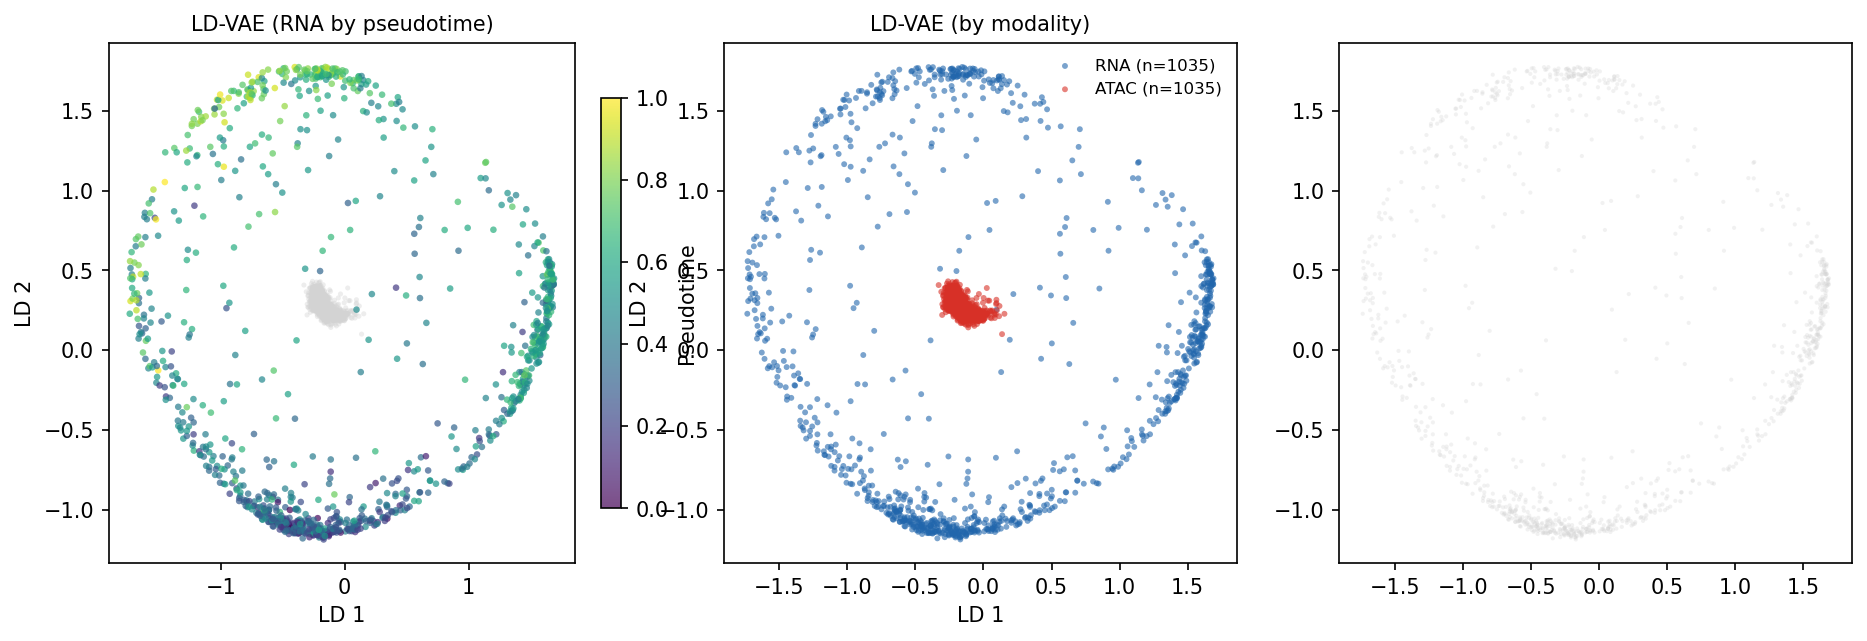

In [20]:
grn.eval(); vel_head.eval(); cell_encoder.eval()
with torch.no_grad():
    z_rna = ld_decoder(cell_encoder.encoder(X_t))[0].cpu().numpy()
    z_atac = ld_decoder(cell_encoder.encoder(torch.tensor(gene_activity, dtype=torch.float32)))[0].cpu().numpy()
    scaler = StandardScaler()
    z_rna_plot  = scaler.fit_transform(z_rna)
    z_atac_plot = scaler.transform(z_atac)
    gl = ld_decoder.get_gene_loadings()
    gl_plot = gl * (2.0 / (np.abs(gl).max() + 1e-8))

plot_ld_embedding(z_rna_plot, pseudo_norm, gl_plot, A_genes,
                  z_2d_atac=z_atac_plot, highlight_genes=MARKER_GENES,
                  save_path=f"{OUT_DIR}/ld_embedding_biplot.png")
print(f"RNA z std/dim:  {z_rna.std(0).round(3)}")
print(f"ATAC z std/dim: {z_atac.std(0).round(3)}")

## Step 16: Velocity projection + scVelo-style stream plot (the arrow plot)

In [21]:
# use the saved run (run0/OUT_DIR). project_to_2d gives the GRN/ATAC DIRECTIONAL term.
V_pred   = np.load(f"{OUT_DIR}/V_pred.npy")
V_proj2d = project_to_2d(V_pred, V_dec2, X, k=20, scale=1.0, drift_correct=True)

# light neighbor smoothing of the directional term (no pseudotime involved)
nn_vis = NearestNeighbors(n_neighbors=31).fit(V_dec2)
_, idx_vis = nn_vis.kneighbors(V_dec2); idx_vis = idx_vis[:, 1:]
V_smooth = 0.7 * V_proj2d + 0.3 * V_proj2d[idx_vis].mean(1)

# recompute the chromatin-rooted progression (idempotent; matches Step 12b) so this cell can
# run standalone from saved arrays. tau roots the flow; the GRN/ATAC velocity refines it.
_root_score = compute_root_score(atac_z, rna_z)
if ROOT_MODE == "manual" and ROOT_CELLS is not None:
    _root_score = np.zeros(len(_root_score), np.float32); _root_score[np.asarray(ROOT_CELLS)] = 1.0
tau_root, _, _root_set = chromatin_rooted_progression(
    ROOT_SPACE, _root_score, k=VEL_FIELD_K, root_frac=VEL_ROOT_FRAC)

# rooted field: +grad(tau) backbone (fans out of origin) + forward-gated GRN/ATAC refinement
V_field = build_rooted_field(V_dec2, V_smooth, tau_root, k=VEL_FIELD_K,
                             speed_floor=VEL_SPEED_FLOOR,
                             V_pred_norm=np.linalg.norm(V_pred, axis=1))

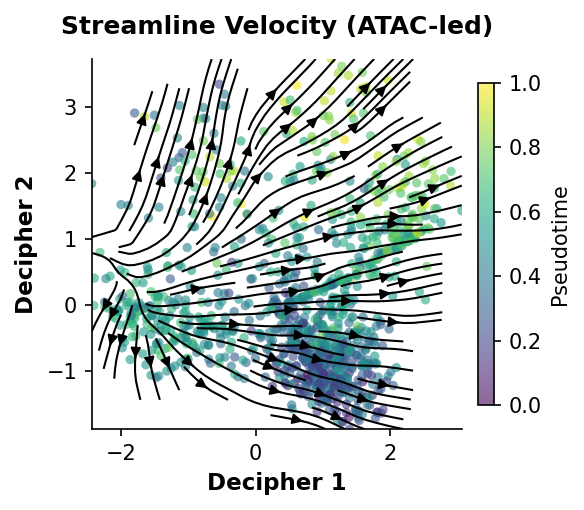

In [22]:
fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)
scv = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=pseudo_norm, cmap="viridis",
                 s=20, alpha=0.6, edgecolors='none', rasterized=True)

Xg, Yg, U, W = field_to_grid(V_dec2, V_field, grid_n=120)   # density-masked, origin kept
ax.streamplot(Xg, Yg, U, W, color="black", density=1.3, linewidth=1,
              arrowsize=1, arrowstyle='-|>', minlength=0.15,
              integration_direction='both', zorder=3)
ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("Streamline Velocity (ATAC-led)", fontsize=12, pad=12, fontweight='bold')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
cbar = plt.colorbar(scv, ax=ax, fraction=0.04, pad=0.04); cbar.set_label("Pseudotime")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/velocity_stream.png", bbox_inches='tight', dpi=150)
plt.show()

## Step 17: GRN mixing diagnostics (temperature = 1.0)

The per-atom maps below are drawn at the **true inference temperature (1.0)**. Committed
cells (branch tips) should be dark for one atom; transition cells should show intermediate
values across ≥2 atoms.

Mean mixing weight/atom: [0.084 0.33  0.232 0.355]
Std  mixing weight/atom: [0.11  0.176 0.117 0.136]
Mean entropy: 1.123 / 1.386 max (want ~0.3-0.7 of max: mixed transitions, committed tips)
Fraction of cells that are 'committed' (max weight > 0.8): 0.0%


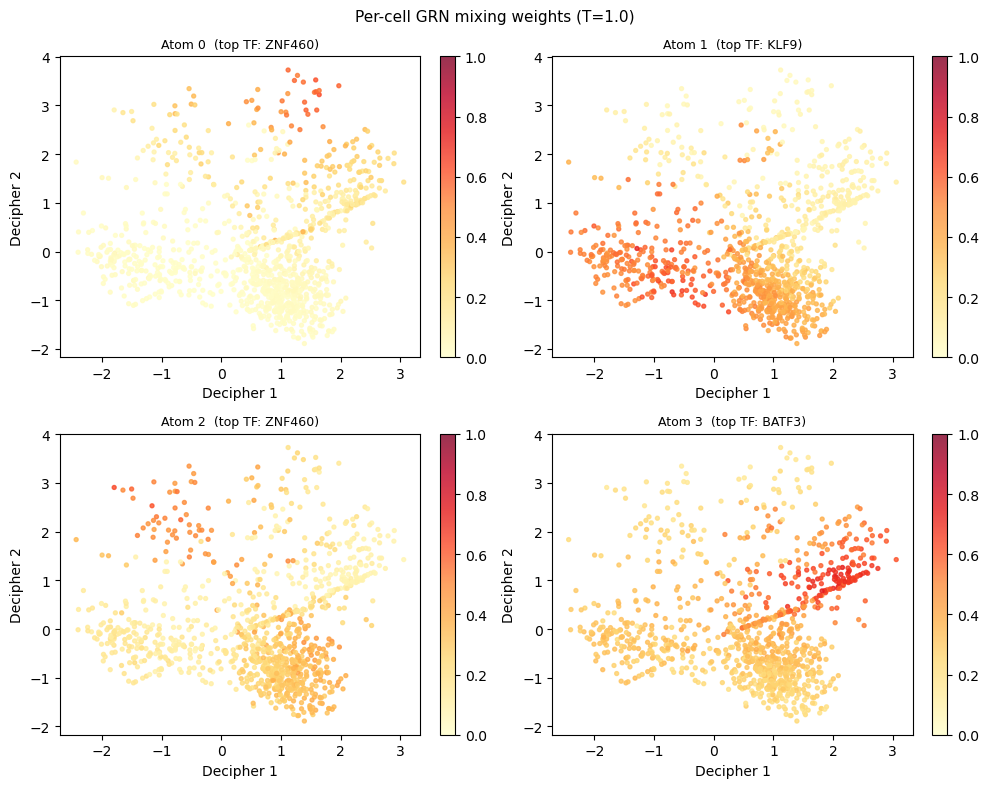

In [23]:
grn.eval(); cell_encoder.eval()
with torch.no_grad():
    W_soft = cell_encoder(X_t, temperature=1.0).numpy()      # (N, D) — what we actually use

ent = -(W_soft * np.log(W_soft + 1e-8)).sum(1)
print("Mean mixing weight/atom:", W_soft.mean(0).round(3))
print("Std  mixing weight/atom:", W_soft.std(0).round(3))
print(f"Mean entropy: {ent.mean():.3f} / {np.log(D_ATOMS):.3f} max "
      f"(want ~0.3-0.7 of max: mixed transitions, committed tips)")
print(f"Fraction of cells that are 'committed' (max weight > 0.8): {(W_soft.max(1) > 0.8).mean():.1%}")

fig, axes = plt.subplots(2, (D_ATOMS + 1) // 2, figsize=(5 * ((D_ATOMS + 1) // 2), 8))
axes = np.atleast_1d(axes).flatten()
for d in range(D_ATOMS):
    ax = axes[d]
    scv = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=W_soft[:, d], cmap='YlOrRd',
                     s=8, alpha=0.8, vmin=0, vmax=1)
    plt.colorbar(scv, ax=ax, fraction=0.04)
    A_atom = grn.A_dict[d].detach().cpu().numpy()
    top_tf = A_tfs[np.abs(A_atom).sum(0).argmax()]
    ax.set_title(f"Atom {d}  (top TF: {top_tf})", fontsize=9)
    ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
for j in range(D_ATOMS, len(axes)):
    axes[j].axis('off')
plt.suptitle("Per-cell GRN mixing weights (T=1.0)", fontsize=11)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/atom_weights_spatial.png", dpi=150, bbox_inches='tight')
plt.show()

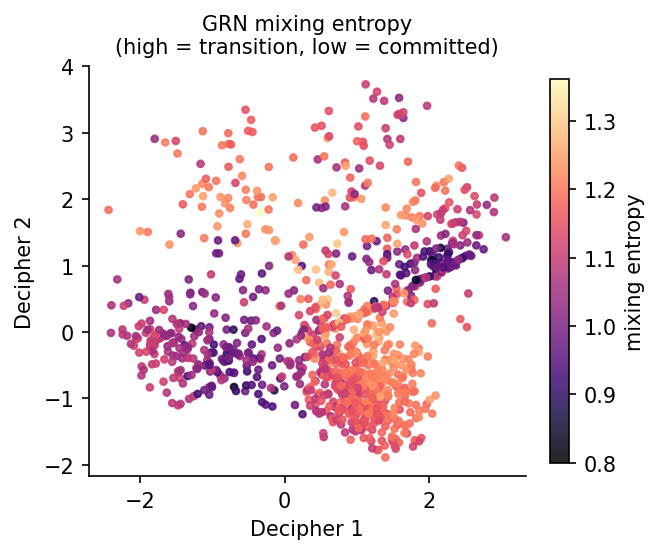

In [24]:
# entropy map: high in transition regions, low at committed tips (the desired pattern)
fig, ax = plt.subplots(figsize=(4.5, 3.8), dpi=150)
scv = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=ent, cmap='magma', s=10, alpha=0.85)
plt.colorbar(scv, ax=ax, fraction=0.04, label='mixing entropy')
ax.set_title("GRN mixing entropy\n(high = transition, low = committed)", fontsize=10)
ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/mixing_entropy.png", dpi=150, bbox_inches='tight')
plt.show()

## Step 18: Downstream helpers + marker expression

In [ ]:
def top_tf_targets(A_learned, A_tfs, A_genes, tf_name, n=20):
    if tf_name not in A_tfs:
        raise ValueError(f"{tf_name} not in A_tfs")
    t = np.where(A_tfs == tf_name)[0][0]
    col = A_learned[:, t]
    top = np.argsort(-np.abs(col))[:n]
    return [(A_genes[i], float(col[i])) for i in top]

A_learned = np.load(f"{OUT_DIR}/A_learned.npy")
frac_pos = float(np.mean(V_pred.mean(1) > 0))
print(f"Cells with net positive velocity: {frac_pos:.1%}")
print(f"\nTop 10 targets of {A_tfs[0]}:")
for g, w in top_tf_targets(A_learned, A_tfs, A_genes, A_tfs[0], n=10):
    print(f"  {g:20s} weight={w:+.4f}")

In [ ]:
# continuous marker expression across Decipher space (sanity check for lineages)
plot_genes = [g for g in MARKER_GENES + ['GATA2', 'LMO2'] if g in rna_adata.var_names]
sc.pl.embedding(rna_adata, basis=DECIPHER_BASIS, color=plot_genes, cmap='Reds',
                frameon=False, ncols=3, wspace=0.25, hspace=0.25, show=True)

---

## Appendix A (optional): velocity robustness across runs

Requires `NUM_RUNS > 1`. Compares 2D arrow direction agreement across runs.

In [ ]:
import seaborn as sns
from scipy.stats import spearmanr

def velocity_robustness_analysis(run_vpreds, pseudo_norm, V_dec2, X, save_path):
    N_runs = len(run_vpreds)
    v2d = [project_to_2d(vp, V_dec2, X, k=20, scale=1.0) for vp in run_vpreds]

    cos_mat = np.zeros((N_runs, N_runs))
    for i in range(N_runs):
        for j in range(N_runs):
            a, b = v2d[i], v2d[j]
            na = np.linalg.norm(a, axis=1, keepdims=True) + 1e-8
            nb = np.linalg.norm(b, axis=1, keepdims=True) + 1e-8
            cos_mat[i, j] = float(((a / na) * (b / nb)).sum(1).mean())

    angles = np.array([np.arctan2(v[:, 1], v[:, 0]) for v in v2d])
    R = np.sqrt(np.sin(angles).mean(0) ** 2 + np.cos(angles).mean(0) ** 2)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)
    sns.heatmap(cos_mat, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, ax=axes[0],
                xticklabels=[f"R{i}" for i in range(N_runs)],
                yticklabels=[f"R{i}" for i in range(N_runs)])
    axes[0].set_title("2D direction agreement (cosine)")
    scv = axes[1].scatter(V_dec2[:, 0], V_dec2[:, 1], c=R, cmap='RdYlGn',
                          vmin=0, vmax=1, s=8, alpha=0.8)
    plt.colorbar(scv, ax=axes[1], fraction=0.04, label='consistency R')
    axes[1].set_title("Per-cell arrow consistency")
    off = cos_mat[~np.eye(N_runs, dtype=bool)]
    axes[2].axis('off')
    axes[2].text(0.05, 0.9,
                 f"runs: {N_runs}\nmean off-diag cosine: {off.mean():.3f}\n"
                 f"min cosine: {off.min():.3f}\nmean R: {R.mean():.3f}\n"
                 f"% cells R>0.7: {(R>0.7).mean():.1%}",
                 transform=axes[2].transAxes, va='top', family='monospace',
                 bbox=dict(boxstyle='round', facecolor='lightyellow'))
    for a in axes[:2]:
        a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)
    plt.tight_layout(); plt.savefig(save_path, bbox_inches='tight', dpi=150); plt.show()
    return {"mean_cosine": float(off.mean()), "mean_R": float(R.mean())}

if NUM_RUNS > 1:
    run_vpreds = [np.load(os.path.join(OUT_DIR, f"run{i}", "V_pred.npy")) for i in range(NUM_RUNS)]
    res = velocity_robustness_analysis(run_vpreds, pseudo_norm, V_dec2, X,
                                       save_path=f"{OUT_DIR}/velocity_robustness.png")
    print(res)

## Appendix B (optional): CellOracle GRN comparison

Runs only if `CELLORACLE_A` exists. Compares the learned population GRN (`A_learned`,
gene × TF) against a CellOracle matrix on their shared subspace via per-TF Spearman.

In [ ]:
if os.path.exists(CELLORACLE_A):
    from scipy.stats import spearmanr
    co = np.load(CELLORACLE_A)                       # expected (n_genes, n_tfs) or transpose
    A_ours = np.load(f"{OUT_DIR}/A_learned.npy")     # (G, T)
    if co.shape == A_ours.T.shape:
        co = co.T
    if co.shape == A_ours.shape:
        per_tf = []
        for t in range(A_ours.shape[1]):
            a, b = A_ours[:, t], co[:, t]
            support = (np.abs(a) + np.abs(b)) > 0
            if support.sum() > 5:
                rho, _ = spearmanr(a[support], b[support])
                per_tf.append(rho)
        per_tf = np.array([r for r in per_tf if np.isfinite(r)])
        print(f"Per-TF Spearman vs CellOracle: mean={per_tf.mean():.3f} (n={len(per_tf)} TFs)")
        plt.figure(figsize=(5, 3.5), dpi=150)
        plt.hist(per_tf, bins=25, color='#4C72B0', alpha=0.85)
        plt.axvline(per_tf.mean(), color='red', ls='--', label=f"mean {per_tf.mean():.2f}")
        plt.xlabel("per-TF Spearman"); plt.ylabel("count"); plt.legend()
        plt.title("GRN agreement vs CellOracle"); plt.tight_layout(); plt.show()
    else:
        print(f"Shape mismatch: ours {A_ours.shape} vs CellOracle {co.shape}; align manually.")
else:
    print(f"No CellOracle file at {CELLORACLE_A} — skipping comparison.")